# Cold Chain Forecasting — Air Temperature & Humidity (Residual LSTM, PyTorch)

Predict the next **30 minutes** of `t_air_c` and `rh_pct` from the previous **120 minutes** of sensor readings.

**Critical structural note:** this dataset is **200 independent trips**, not one continuous time series.
Every interpolation, rolling op, and sliding window must be done **inside `groupby("trip_id")`**.
A window that spans the end of one trip and the start of the next describes a physical transition
that never happened.

**Second structural note — this is what the first version of this notebook got wrong.**
A network that predicts the *absolute level* of temperature has to spend most of its capacity
remembering what the current temperature is. Squeezing 120 timesteps through a small final
hidden state blurs exactly the number that matters most: the last observed value. The symptom is
unmistakable in the per-horizon plot — the model is **worse than persistence at h=1**, and that
level error is then baked into all 30 horizons.

So this version is **anchored**: each window's target channels are expressed relative to the last
observed value, the network predicts the *deviation*, and the anchor is added back at the output.
The final layer is zero-initialised, so the model literally starts as the persistence baseline and
can only move away from it by reducing loss.

## 1. Setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# Window configuration
N_PAST   = 120   # minutes of history fed to the model
N_FUTURE = 30    # minutes to forecast

# Shortest trip in the data is 241 rows, so N_PAST + N_FUTURE must stay under 241
assert N_PAST + N_FUTURE <= 241, "Window too long - some trips would be dropped entirely"

device: cuda


In [3]:
CSV_PATH = "data/coldchain_sensors.csv" 

coldChainDF = pd.read_csv(CSV_PATH)
print(coldChainDF.shape)
coldChainDF.head()

(109563, 12)


,trip_id,minute,t_air_c,rh_pct,t_ambient_c,rh_ambient_pct,door_open,vehicle_moving,compressor_on,defrost_on,hour_of_day,split
0,TRIP_0000,0,5.7,86.4,31.8,43.7,0,1,1,0,7.273,val
1,TRIP_0000,1,5.2,88.4,31.8,44.5,0,1,1,0,7.289,val
2,TRIP_0000,2,5.3,85.4,31.6,43.4,0,1,1,0,7.306,val
3,TRIP_0000,3,5.0,85.3,31.7,43.3,0,1,1,0,7.323,val
4,TRIP_0000,4,4.9,84.6,32.1,45.1,0,1,1,0,7.339,val


In [4]:
print("trips:", coldChainDF.trip_id.nunique())
print("trips per split:")
print(coldChainDF.groupby("split").trip_id.nunique())

# Each trip must live in exactly one split (this is what makes the split leak-free)
assert (coldChainDF.groupby("trip_id").split.nunique() == 1).all()

# Sampling must be exactly 1 minute with no gaps inside a trip
diffs = coldChainDF.groupby("trip_id")["minute"].diff().dropna().unique()
print("minute diffs:", diffs)
assert set(diffs) == {1.0}

print("\nmissing values:")
print(coldChainDF.isna().sum()[lambda s: s > 0])

trips: 200
trips per split:
split
test      30
train    140
val       30
Name: trip_id, dtype: int64
minute diffs: [1.]

missing values:
t_air_c    344
rh_pct     344
dtype: int64


## 2. Handle missing values (per trip)

`t_air_c` and `rh_pct` are the only columns with gaps, and they always go missing **together**
(sensor dropout, not independent noise). The gaps are 344 values across 148 trips, in runs of
only 1–2 minutes — short enough that linear interpolation is safe.

The `groupby` is what keeps the interpolation from bleeding the tail of one trip into the head
of the next.

In [5]:
TARGETS = ["t_air_c", "rh_pct"]

# Inspect gap run lengths before deciding to interpolate
flag = coldChainDF.t_air_c.isna()
runs = (flag != flag.shift()).cumsum()[flag].value_counts().value_counts().sort_index()
print("gap run lengths (length -> count):")
print(runs)

coldChainDF[TARGETS] = (
    coldChainDF.groupby("trip_id")[TARGETS]
    .transform(lambda s: s.interpolate(limit_direction="both"))
)

assert coldChainDF[TARGETS].isna().sum().sum() == 0
print("\nno missing values remaining")

gap run lengths (length -> count):
count
1    340
2      2
Name: count, dtype: int64

no missing values remaining


## 3. Cyclical encoding of `hour_of_day`

`hour_of_day` runs 0–24 and wraps around 76 times in this dataset. Fed in raw, the model would
treat 23.9 and 0.1 as maximally far apart when they are one minute apart. Sine/cosine encoding
puts them next to each other on a circle.

In [6]:
coldChainDF["hod_sin"] = np.sin(2 * np.pi * coldChainDF.hour_of_day / 24)
coldChainDF["hod_cos"] = np.cos(2 * np.pi * coldChainDF.hour_of_day / 24)

coldChainDF[["hour_of_day", "hod_sin", "hod_cos"]].head()

,hour_of_day,hod_sin,hod_cos
0,7.273,0.944977,-0.327135
1,7.289,0.943599,-0.331091
2,7.306,0.942116,-0.335287
3,7.323,0.940614,-0.339477
4,7.339,0.939184,-0.343414


## 4. Feature groups

Three kinds of column, treated differently at scaling time:

- **Continuous** — standardized.
- **Binary flags** — left alone. Standardizing 0/1 columns just adds noise and makes them
  harder to interpret.
- **Cyclical** — already in [-1, 1], leave as-is.

This is the **past-only** formulation: the model sees the last `N_PAST` minutes of *everything*
and predicts the next `N_FUTURE` minutes of temp and humidity.

In [7]:
CONT_FEATS = ["t_air_c", "rh_pct", "t_ambient_c", "rh_ambient_pct"]
BIN_FEATS  = ["door_open", "vehicle_moving", "compressor_on", "defrost_on"]
CYC_FEATS  = ["hod_sin", "hod_cos"]

FEATURES = CONT_FEATS + BIN_FEATS + CYC_FEATS
N_FEATURES = len(FEATURES)

print(f"{N_FEATURES} input features:", FEATURES)
print("targets:", TARGETS)

10 input features: ['t_air_c', 'rh_pct', 't_ambient_c', 'rh_ambient_pct', 'door_open', 'vehicle_moving', 'compressor_on', 'defrost_on', 'hod_sin', 'hod_cos']
targets: ['t_air_c', 'rh_pct']


## 5. Scaling — fit on train rows only

Two separate scalers:

- `feat_scaler` for the continuous inputs.
- `targ_scaler` for the two targets alone, so predictions can be inverted back to °C and %RH
  without slicing columns out of a wider scaler.

Both are fit on **train rows only**, then applied to all three splits. Fitting on the full frame
is the single most common leak in this kind of pipeline.

In [8]:
train_mask = coldChainDF.split == "train"

feat_scaler = StandardScaler().fit(coldChainDF.loc[train_mask, CONT_FEATS])
targ_scaler = StandardScaler().fit(coldChainDF.loc[train_mask, TARGETS])

scaled = coldChainDF.copy()
scaled[CONT_FEATS] = feat_scaler.transform(coldChainDF[CONT_FEATS])

# Scaled copies of the targets, kept in separate columns so the originals stay readable
Y_COLS = ["y_t_air", "y_rh"]
scaled[Y_COLS] = targ_scaler.transform(coldChainDF[TARGETS])

scaled[CONT_FEATS + Y_COLS].describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
t_air_c,0.035106,0.994527,-2.109665,6.250751
rh_pct,0.025986,0.969864,-3.637361,4.639460
t_ambient_c,0.052379,1.030524,-1.987588,3.043009
rh_ambient_pct,-0.051578,0.978990,-2.094753,2.468990
y_t_air,0.035106,0.994527,-2.109665,6.250751
y_rh,0.025986,0.969864,-3.637361,4.639460


## 6. Build windows inside each trip — anchored

`make_windows` loops over trips within a single split and never crosses a trip boundary.

It also returns `anchor` — the final observed target value in each input window. The anchor does
three jobs here:

1. it is the persistence baseline prediction,
2. it is subtracted from the `t_air_c` / `rh_pct` channels *inside* the window, so the network
   sees recent **dynamics** rather than a trip-specific absolute level (this is what stops it
   memorising the 140 training trips),
3. it is appended back as two constant channels, so absolute level is still available if it
   genuinely carries signal.

`stride` is new. At stride 1, consecutive windows share 119 of 120 timesteps — they are near
duplicates, so 55k windows carry nowhere near 55k windows' worth of information. Stride 3 on
train cuts epoch time by ~3x and decorrelates the batches.

In [9]:
T_IDX = FEATURES.index("t_air_c")
H_IDX = FEATURES.index("rh_pct")


def make_windows(df, split, n_past=N_PAST, n_future=N_FUTURE, stride=1):
    '''Slide windows within each trip. Never crosses trip boundaries.

    Returns X anchored: the two target channels inside the window are expressed
    relative to the last observed value, and that anchor is appended as two
    extra constant channels.
    '''
    X, y, anchor = [], [], []
    subset = df[df.split == split]

    for _, g in subset.groupby("trip_id", sort=False):
        feats = g[FEATURES].values.astype(np.float32)
        targs = g[Y_COLS].values.astype(np.float32)
        n_windows = len(g) - n_past - n_future + 1
        if n_windows <= 0:
            continue  # trip too short for this window size
        for i in range(0, n_windows, stride):
            w = feats[i : i + n_past].copy()
            a = targs[i + n_past - 1]                     # last observed target
            w[:, T_IDX] -= a[0]
            w[:, H_IDX] -= a[1]
            w = np.concatenate([w, np.repeat(a[None, :], n_past, axis=0)], axis=1)
            X.append(w)
            y.append(targs[i + n_past : i + n_past + n_future])
            anchor.append(a)

    return (
        np.array(X, dtype=np.float32),
        np.array(y, dtype=np.float32),
        np.array(anchor, dtype=np.float32),
    )


X_train, y_train, anchor_train = make_windows(scaled, "train", stride=3)
X_val,   y_val,   anchor_val   = make_windows(scaled, "val")
X_test,  y_test,  anchor_test  = make_windows(scaled, "test")

N_IN = X_train.shape[-1]          # N_FEATURES + 2 anchor channels
print("input channels:", N_IN)
for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{name:5s} X {X.shape}  y {y.shape}")

# Sanity: the last timestep of the target channels must be exactly 0 after centring
assert np.abs(X_train[:, -1, [T_IDX, H_IDX]]).max() < 1e-5
print("\nwindows are anchored at t=0 on the last observed value")

input channels: 12
train X (18408, 120, 12)  y (18408, 30, 2)
val   X (12488, 120, 12)  y (12488, 30, 2)
test  X (12183, 120, 12)  y (12183, 30, 2)

windows are anchored at t=0 on the last observed value


## 7. Persistence baseline — and an honest ceiling

"The next 30 minutes look exactly like the last observed minute."

Cold chain air temperature is heavily autocorrelated, so this baseline is genuinely strong.
It is the number the model has to beat to have learned anything worth having.

The second thing this cell computes matters just as much: a **noise floor**. Smoothing each *true
future* trajectory with a centred 5-minute window is an oracle — it peeks forward, so no causal
model can do it — and whatever is left over is high-frequency jitter that is simply not
predictable from the past. Judge the final MAE against that number, not against zero. If the floor
comes out near the persistence MAE, the headroom on this dataset is small and no architecture
change will rescue it.

In [10]:
from scipy.ndimage import uniform_filter1d


def inverse_targets(arr):
    '''(samples, n_future, 2) in scaled space -> original units.'''
    flat = arr.reshape(-1, 2)
    return targ_scaler.inverse_transform(flat).reshape(arr.shape)


def report(y_true_scaled, y_pred_scaled, label):
    y_true = inverse_targets(y_true_scaled)
    y_pred = inverse_targets(y_pred_scaled)
    err = np.abs(y_true - y_pred)
    rmse = np.sqrt(((y_true - y_pred) ** 2).reshape(-1, 2).mean(axis=0))
    mae = err.reshape(-1, 2).mean(axis=0)
    print(f"{label}")
    print(f"  t_air_c  MAE {mae[0]:.4f} C     RMSE {rmse[0]:.4f}")
    print(f"  rh_pct   MAE {mae[1]:.4f} %RH   RMSE {rmse[1]:.4f}")
    return mae


# Repeat the last observed value across the whole forecast horizon
persist_test = np.repeat(anchor_test[:, None, :], N_FUTURE, axis=1)
baseline_mae = report(y_test, persist_test, "PERSISTENCE BASELINE (test)")

# Oracle smoother -> unpredictable high-frequency component
yt = inverse_targets(y_test)
oracle = uniform_filter1d(yt, size=5, axis=1, mode="nearest")
floor = np.abs(yt - oracle).reshape(-1, 2).mean(axis=0)
print(f"\nunpredictable high-frequency component: t_air {floor[0]:.3f} C, rh {floor[1]:.3f} %RH")
print("a realistic result sits between this floor and the persistence numbers above")

PERSISTENCE BASELINE (test)
  t_air_c  MAE 0.7574 C     RMSE 1.3163
  rh_pct   MAE 2.4309 %RH   RMSE 3.2554

unpredictable high-frequency component: t_air 0.154 C, rh 0.963 %RH
a realistic result sits between this floor and the persistence numbers above


## 8. PyTorch datasets and dataloaders

Wrap the numpy arrays in a plain `Dataset`. `pin_memory=True` and a larger batch on `DataLoader`
speed up GPU transfer if you have a GPU; harmless on CPU.

In [11]:
class WindowDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


BATCH_SIZE = 64

train_ds = WindowDataset(X_train, y_train)
val_ds   = WindowDataset(X_val, y_val)
test_ds  = WindowDataset(X_test, y_test)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=256,        shuffle=False, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=256,        shuffle=False, pin_memory=True)

print(f"train batches: {len(train_loader)}, val batches: {len(val_loader)}, test batches: {len(test_loader)}")

train batches: 288, val batches: 49, test batches: 48


## 9. Model — residual LSTM with a persistence skip connection

Three deliberate choices:

- **The output is a delta.** `forward` pulls the anchor out of the input's last two channels and
  adds it back after the head. The network's job is reduced to "how will this deviate from where
  it is now", which is the only part that needs learning.
- **The head is zero-initialised.** At step 0 the model *is* the persistence baseline. Training
  can only move it off that point by lowering the loss, so the pathological "worse than
  persistence at h=1" regime is unreachable.
- **The last 12 raw timesteps bypass the recurrent stack.** Recent detail reaches the head
  directly instead of surviving a squeeze through the final hidden state.

In [12]:
class ResidualLSTMForecaster(nn.Module):
    '''Predicts y[t+h] - y[t_last] and adds y[t_last] back.

    The anchor is carried around the recurrent stack, so the network never has to
    spend hidden units memorising the current temperature level - it only has to
    model the dynamics on top of it.
    '''

    def __init__(self, n_features, n_future, n_targets,
                 hidden1=96, hidden2=64, dropout=0.15, n_tail=12):
        super().__init__()
        self.n_future = n_future
        self.n_targets = n_targets
        self.n_tail = n_tail                # raw recent steps fed straight to the head

        self.lstm1 = nn.LSTM(n_features, hidden1, batch_first=True)
        self.drop1 = nn.Dropout(dropout)
        self.lstm2 = nn.LSTM(hidden1, hidden2, batch_first=True)
        self.drop2 = nn.Dropout(dropout)

        head_in = hidden2 + n_tail * n_targets
        self.head = nn.Sequential(
            nn.Linear(head_in, 128),
            nn.GELU(),
            nn.Linear(128, n_future * n_targets),
        )
        # Start as an exact copy of the persistence baseline
        nn.init.zeros_(self.head[-1].weight)
        nn.init.zeros_(self.head[-1].bias)

    def forward(self, x):
        # x: (batch, N_PAST, n_features). Last 2 channels are the constant anchor.
        anchor = x[:, -1, -self.n_targets:]                       # (batch, 2)
        tail = x[:, -self.n_tail:, [T_IDX, H_IDX]].reshape(x.size(0), -1)

        out, _ = self.lstm1(x)
        out = self.drop1(out)
        out, (h_n, _) = self.lstm2(out)
        h = self.drop2(h_n[-1])                                   # (batch, hidden2)

        delta = self.head(torch.cat([h, tail], dim=1))
        delta = delta.view(-1, self.n_future, self.n_targets)
        return delta + anchor[:, None, :]                         # back to level space


model = ResidualLSTMForecaster(N_IN, N_FUTURE, len(TARGETS)).to(device)
print(model)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\ntrainable parameters: {n_params:,}")

# At init the model must reproduce persistence exactly
with torch.no_grad():
    chk = model(torch.from_numpy(X_test[:4]).to(device)).cpu().numpy()
assert np.allclose(chk, persist_test[:4], atol=1e-5), "zero-init head is not behaving"
print("initial model == persistence baseline")

ResidualLSTMForecaster(
  (lstm1): LSTM(12, 96, batch_first=True)
  (drop1): Dropout(p=0.15, inplace=False)
  (lstm2): LSTM(96, 64, batch_first=True)
  (drop2): Dropout(p=0.15, inplace=False)
  (head): Sequential(
    (0): Linear(in_features=88, out_features=128, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=128, out_features=60, bias=True)
  )
)

trainable parameters: 102,844
initial model == persistence baseline


## 10. Train

Four changes from the first version, in order of how much they mattered:

- **`nn.L1Loss`, not `SmoothL1Loss()`.** `SmoothL1Loss` defaults to `beta=1.0`; on standardized
  targets almost every error is far below 1.0, so it never left its quadratic region — that was
  MSE in disguise. MSE fits the conditional **mean**, the reported metric is MAE which wants the
  conditional **median**, and on data this noisy the gap is real.
- **Gradient clipping.** 120 unrolled steps is enough for the occasional exploding batch.
- **`AdamW` with weight decay** instead of plain Adam.
- **`PATIENCE` raised to 20.** The previous run early-stopped at epoch 13 and restored weights
  from **epoch 3** — the evaluated model had seen the data three times. With the anchored
  formulation the train/val gap should stay closed long enough to actually train.

`validation_data` is a **separate loader built from the `split` column**, not a random slice — do
not shuffle trips into it.

In [13]:
import copy

EPOCHS      = 150
PATIENCE    = 20        # early stopping
LR_PATIENCE = 6         # ReduceLROnPlateau
LR_FACTOR   = 0.5
MIN_LR      = 1e-5
CLIP        = 1.0       # gradient norm

criterion = nn.L1Loss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=LR_FACTOR, patience=LR_PATIENCE, min_lr=MIN_LR
)


def run_epoch(loader, model, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train(is_train)
    total_loss, n = 0.0, 0

    with torch.set_grad_enabled(is_train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            preds = model(xb)
            loss = criterion(preds, yb)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), CLIP)
                optimizer.step()

            bs = xb.size(0)
            total_loss += loss.item() * bs
            n += bs

    return total_loss / n


history = {"loss": [], "val_loss": []}
best_val_loss = float("inf")
best_state = None
epochs_no_improve = 0

for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(train_loader, model, criterion, optimizer)
    val_loss   = run_epoch(val_loader, model, criterion, optimizer=None)
    scheduler.step(val_loss)

    history["loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    improved = val_loss < best_val_loss - 1e-6
    if improved:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1

    current_lr = optimizer.param_groups[0]["lr"]
    print(f"epoch {epoch:3d}  loss {train_loss:.4f}  val_loss {val_loss:.4f}  "
          f"lr {current_lr:.2e}" + ("  *" if improved else ""))

    if epochs_no_improve >= PATIENCE:
        print(f"\nearly stopping at epoch {epoch} (no improvement for {PATIENCE} epochs)")
        break

model.load_state_dict(best_state)   # restore_best_weights equivalent
print(f"\nrestored best weights, val_loss = {best_val_loss:.4f}")
print(f"best epoch: {int(np.argmin(history['val_loss'])) + 1} of {len(history['val_loss'])}")

epoch   1  loss 0.2758  val_loss 0.2490  lr 1.00e-03  *
epoch   2  loss 0.2579  val_loss 0.2450  lr 1.00e-03  *
epoch   3  loss 0.2523  val_loss 0.2427  lr 1.00e-03  *
epoch   4  loss 0.2499  val_loss 0.2409  lr 1.00e-03  *
epoch   5  loss 0.2474  val_loss 0.2457  lr 1.00e-03
epoch   6  loss 0.2464  val_loss 0.2381  lr 1.00e-03  *
epoch   7  loss 0.2438  val_loss 0.2392  lr 1.00e-03
epoch   8  loss 0.2416  val_loss 0.2378  lr 1.00e-03  *
epoch   9  loss 0.2394  val_loss 0.2380  lr 1.00e-03
epoch  10  loss 0.2376  val_loss 0.2427  lr 1.00e-03
epoch  11  loss 0.2363  val_loss 0.2389  lr 1.00e-03
epoch  12  loss 0.2352  val_loss 0.2425  lr 1.00e-03
epoch  13  loss 0.2336  val_loss 0.2386  lr 1.00e-03
epoch  14  loss 0.2308  val_loss 0.2414  lr 1.00e-03
epoch  15  loss 0.2296  val_loss 0.2442  lr 5.00e-04
epoch  16  loss 0.2249  val_loss 0.2412  lr 5.00e-04
epoch  17  loss 0.2229  val_loss 0.2476  lr 5.00e-04
epoch  18  loss 0.2220  val_loss 0.2428  lr 5.00e-04
epoch  19  loss 0.2206  val_

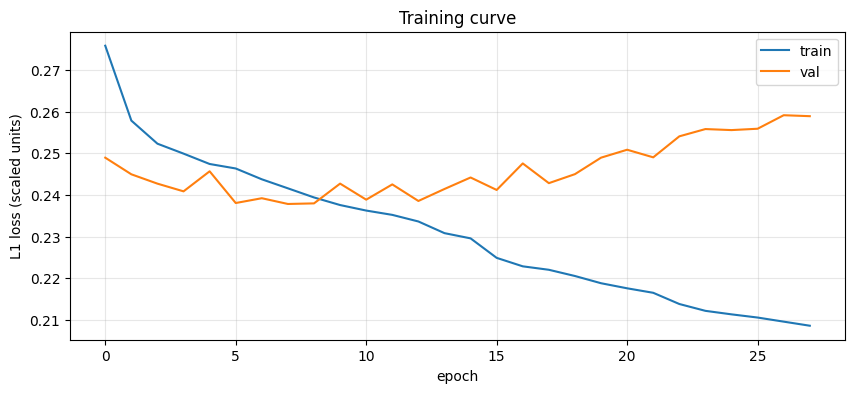

In [14]:
plt.figure(figsize=(10, 4))
plt.plot(history["loss"], label="train")
plt.plot(history["val_loss"], label="val")
plt.xlabel("epoch"); plt.ylabel("L1 loss (scaled units)"); plt.legend()
plt.title("Training curve")
plt.grid(alpha=0.3)
plt.show()

# If val turns up within the first few epochs again, the model is still
# memorising trips rather than learning dynamics - look at the anchoring first,
# not at the layer sizes.

## 11. Evaluate against the baseline

In [15]:
model.eval()
preds = []
with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(device)
        preds.append(model(xb).cpu().numpy())
y_pred = np.concatenate(preds, axis=0)

model_mae = report(y_test, y_pred, "RESIDUAL LSTM (test)")
print()
baseline_mae = report(y_test, persist_test, "PERSISTENCE (test)")

print("\nimprovement over baseline:")
for i, name in enumerate(TARGETS):
    delta = (baseline_mae[i] - model_mae[i]) / baseline_mae[i] * 100
    verdict = "beats baseline" if delta > 0 else "WORSE THAN BASELINE"
    print(f"  {name:10s} {delta:+6.1f}%   {verdict}")

# The check the unanchored model failed: at h=1 a sane model can never be worse
# than simply repeating the last observed value.
y_true_inv  = inverse_targets(y_test)
y_pred_inv  = inverse_targets(y_pred)
persist_inv = inverse_targets(persist_test)

m1 = np.abs(y_true_inv[:, 0, :] - y_pred_inv[:, 0, :]).mean(axis=0)
b1 = np.abs(y_true_inv[:, 0, :] - persist_inv[:, 0, :]).mean(axis=0)
print(f"\nh=1 MAE   model {m1.round(4)}   persistence {b1.round(4)}")
assert (m1 <= b1 * 1.02).all(), "still not anchored at h=1 - check the skip connection"

RESIDUAL LSTM (test)
  t_air_c  MAE 0.5654 C     RMSE 1.1695
  rh_pct   MAE 1.8762 %RH   RMSE 2.6231

PERSISTENCE (test)
  t_air_c  MAE 0.7574 C     RMSE 1.3163
  rh_pct   MAE 2.4309 %RH   RMSE 3.2554

improvement over baseline:
  t_air_c     +25.4%   beats baseline
  rh_pct      +22.8%   beats baseline

h=1 MAE   model [0.2106 1.2569]   persistence [0.2584 1.5755]


### Error by forecast horizon

Aggregate MAE hides the shape of the problem. Three things to read off this plot:

- **At h=1 the model must sit on or below the persistence line.** If it does not, the forecast is
  not anchored to the present and every horizon inherits that offset. This is exactly what went
  wrong before anchoring.
- **Error should grow with horizon.** Flat means the model is echoing the last input value.
- **The dotted noise floor is the realistic target.** The gap between the persistence curve and
  the floor is all the headroom that exists.

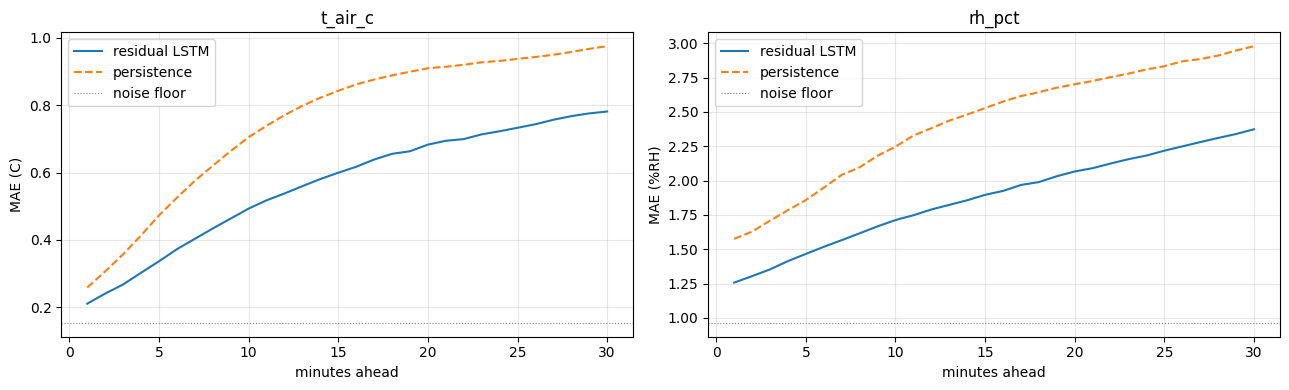

In [16]:
steps = np.arange(1, N_FUTURE + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i, (ax, name, unit) in enumerate(zip(axes, TARGETS, ["C", "%RH"])):
    ax.plot(steps, np.abs(y_true_inv[:, :, i] - y_pred_inv[:, :, i]).mean(axis=0), label="residual LSTM")
    ax.plot(steps, np.abs(y_true_inv[:, :, i] - persist_inv[:, :, i]).mean(axis=0), "--", label="persistence")
    ax.axhline(floor[i], color="gray", lw=0.8, ls=":", label="noise floor")
    ax.set_xlabel("minutes ahead"); ax.set_ylabel(f"MAE ({unit})")
    ax.set_title(name); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Spot-check a few forecasts

What to look for: the predicted line should **start where the history ends**. In the unanchored
version it frequently started half a degree above or below the last grey point, which is the
whole bug in one picture.

Do not be alarmed that the prediction is much smoother than the actual. The actual is dominated
by minute-level jitter that no causal model can recover; a flat-ish forecast through the middle of
it is the MAE-optimal answer, not a failure.

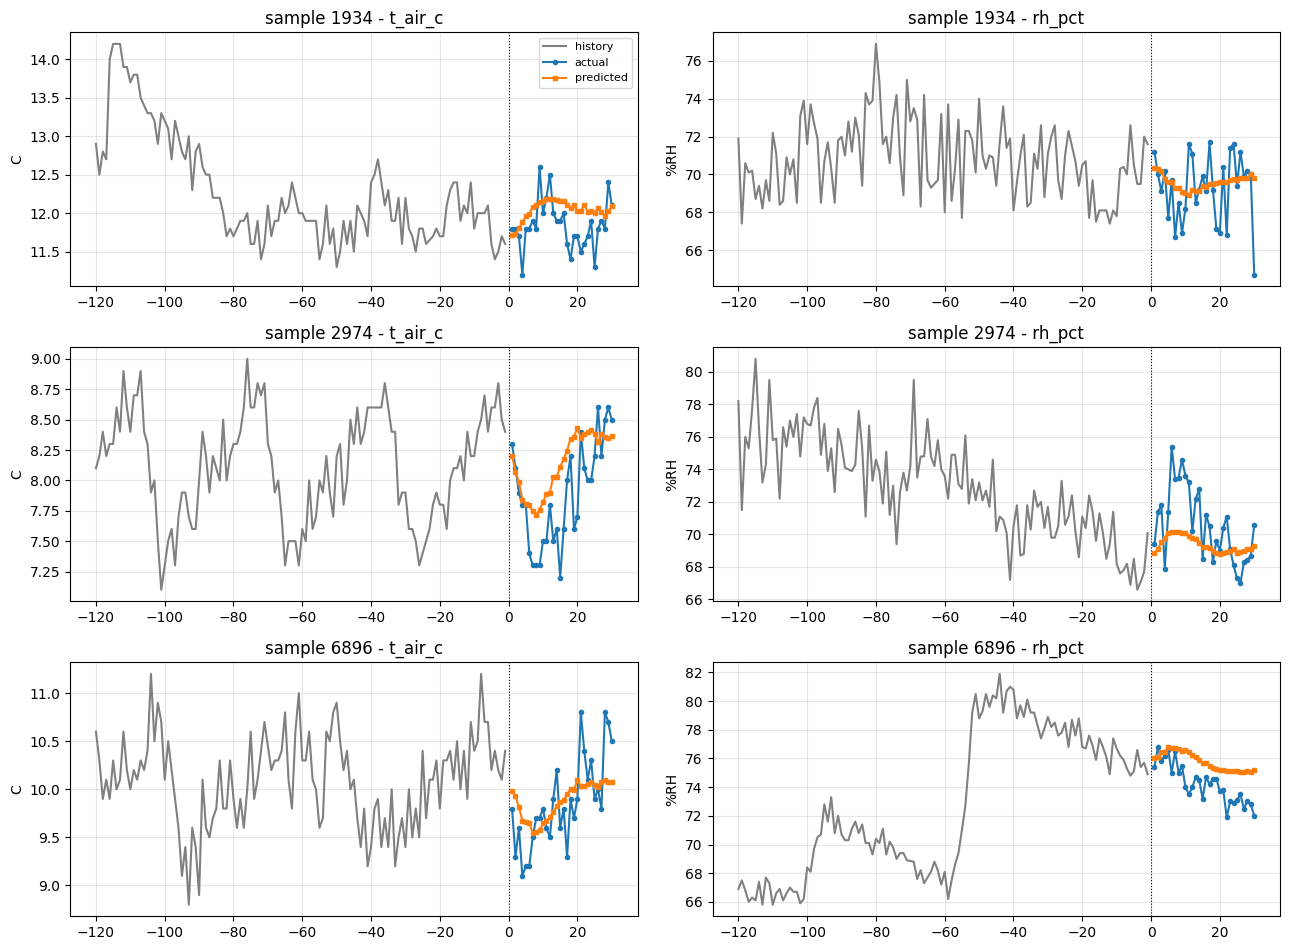

In [17]:
# The target channels inside X_test are now anchor-centred, so the anchor has to
# be added back before inverse_transform or the history line lands in the wrong
# place on the y-axis.
idx = np.random.choice(len(X_test), 3, replace=False)
fig, axes = plt.subplots(len(idx), 2, figsize=(13, 3.2 * len(idx)))

for r, j in enumerate(idx):
    centred = X_test[j][:, [T_IDX, H_IDX]]
    hist = targ_scaler.inverse_transform(centred + anchor_test[j])
    for c, (name, unit) in enumerate(zip(TARGETS, ["C", "%RH"])):
        ax = axes[r, c]
        ax.plot(np.arange(-N_PAST, 0), hist[:, c], color="gray", label="history")
        ax.plot(steps, y_true_inv[j, :, c], "o-", ms=3, label="actual")
        ax.plot(steps, y_pred_inv[j, :, c], "s-", ms=3, label="predicted")
        ax.axvline(0, color="k", lw=0.8, ls=":")
        ax.set_title(f"sample {j} - {name}"); ax.set_ylabel(unit); ax.grid(alpha=0.3)
        if r == 0 and c == 0:
            ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 12. Save model and scalers together

The scalers are not optional artifacts — without them the saved model produces numbers in
standardized space that cannot be converted back to °C or %RH.

`state_dict` + a small config dict is the portable PyTorch save pattern — it needs the model
class definition available at load time, which is why `config.json` also records the constructor
arguments. Note `n_features` is now `N_IN`, i.e. **12** not 10, because of the two anchor
channels; loading with 10 will fail at the first matmul.

In [18]:
import joblib, json, os

os.makedirs("artifacts", exist_ok=True)

torch.save(model.state_dict(), "artifacts/coldchain_lstm.pt")
joblib.dump({"feat_scaler": feat_scaler, "targ_scaler": targ_scaler}, "artifacts/scalers.joblib")

with open("artifacts/config.json", "w") as f:
    json.dump({
        "n_past": N_PAST, "n_future": N_FUTURE,
        "features": FEATURES, "cont_feats": CONT_FEATS, "targets": TARGETS,
        "n_features": int(N_IN),          # includes the 2 anchor channels
        "hidden1": 96, "hidden2": 64, "dropout": 0.15, "n_tail": 12,
        "anchored": True,
        "t_idx": T_IDX, "h_idx": H_IDX,
    }, f, indent=2)

print("saved to artifacts/")

# To reload later:
#   cfg = json.load(open("artifacts/config.json"))
#   model = ResidualLSTMForecaster(cfg["n_features"], cfg["n_future"], len(cfg["targets"]),
#                                  cfg["hidden1"], cfg["hidden2"], cfg["dropout"], cfg["n_tail"])
#   model.load_state_dict(torch.load("artifacts/coldchain_lstm.pt", map_location=device))
#   model.eval()
#
# IMPORTANT at inference: the input window must be anchor-centred the same way
# make_windows does it, or the skip connection reads the wrong anchor.

saved to artifacts/


## Where to go next

The anchoring fix removes the structural handicap. What is left is a genuinely hard signal
problem: `t_air_c` correlates only weakly with every other column in this file (the strongest is
`door_open` at 0.17), so nearly all of the signal lives in the target's own recent history — which
is precisely what makes persistence strong.

**Set expectations from the noise floor printed in section 7, not from a round number.** On data
with this much minute-level jitter, 25–35% over persistence is a good result. Anything claiming
far more is usually a leak.

Remaining ideas, roughly in order of payoff:

1. **Event-recency features.** Minutes since last door-open, since compressor toggle, since
   defrost-off. A binary flag tells the model the door is shut; a recency counter tells it the
   door shut four minutes ago and the thermal transient is still in progress. This is usually the
   single biggest feature-engineering win on cold-chain data.
2. **Rolling statistics inside the window** — 5/15/60-minute means and standard deviations of
   `t_air_c`, computed per trip. Cheap, and it hands the network a smoothed signal it would
   otherwise have to learn to compute.
3. **Shorten the horizon if the use case allows.** Check the per-horizon plot: if the win over
   persistence collapses after minute 15, a 15-minute forecast is a better product than a bad
   30-minute one.
4. **Quantile heads.** Train three heads at the 10th/50th/90th percentile with pinball loss. For
   cold chain, "how likely are we to breach 8 °C in the next half hour" is the question that
   actually matters, and a point forecast cannot answer it.
5. **Tune `N_PAST`.** 120 was assumed, not measured. Plot the autocorrelation of `t_air_c` per
   trip; if the compressor duty cycle is ~25 minutes, 60 may be enough and trains twice as fast.
6. **Only then make the network bigger.** Capacity has not been the binding constraint at any
   point in this notebook.